> **Portfolio summary:** Testing the CAPM on German stock portfolios: Jensen's alpha, the SML and Fama-MacBeth regressions (group project).
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

In [5]:
# =========================
# 0. Install packages if needed
# =========================
# Uncomment if running in a new environment:
# !pip install yfinance statsmodels pandas numpy matplotlib scipy

In [6]:
# =========================
# 1. Import libraries
# =========================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

In [7]:
# =========================
# 2. Data settings
# =========================

# German stocks, mostly large-cap listed firms.
# You can adjust this list if some tickers fail to download.
tickers = [
    "SAP.DE", "SIE.DE", "ALV.DE", "BMW.DE", "BAS.DE",
    "DTE.DE", "DBK.DE", "ADS.DE", "AIR.DE", "MBG.DE",
    "VOW3.DE", "BAYN.DE", "IFX.DE", "MUV2.DE", "RWE.DE",
    "EOAN.DE", "HEN3.DE", "BEI.DE", "HEI.DE", "FRE.DE",
    "CON.DE", "MRK.DE", "MTX.DE", "PAH3.DE", "ZAL.DE"
]

market_ticker = "^GDAXI"      # DAX index as market proxy
start_date = "2014-01-01"
end_date = "2024-12-31"

# Risk-free proxy: annual rate converted to monthly.
# Change this if you have a better local risk-free rate series.
annual_rf = 0.02
monthly_rf = (1 + annual_rf) ** (1/12) - 1

print(f"Monthly risk-free rate used: {monthly_rf:.4%}")

Monthly risk-free rate used: 0.1652%

In [8]:
# =========================
# 3. Download price data
# =========================
all_tickers = tickers + [market_ticker]

prices = yf.download(
    all_tickers,
    start=start_date,
    end=end_date,
    interval="1mo",
    auto_adjust=True,
    progress=False
)["Close"]

# Remove assets with too much missing data, then align all remaining series.
min_obs_required = int(len(prices) * 0.80)
prices = prices.dropna(axis=1, thresh=min_obs_required).dropna()

returns = prices.pct_change().dropna()

market_return = returns[market_ticker]
stock_returns = returns.drop(columns=[market_ticker])

# Excess returns
market_excess = market_return - monthly_rf
market_excess.name = "Market Excess Return"
stock_excess = stock_returns.sub(monthly_rf)

print("Number of stocks retained:", stock_excess.shape[1])
print("Number of monthly observations:", stock_excess.shape[0])
print("Sample period:", stock_excess.index.min().date(), "to", stock_excess.index.max().date())

stock_excess.head()

Number of stocks retained: 25
Number of monthly observations: 122
Sample period: 2014-11-01 to 2024-12-01

Ticker,ADS.DE,AIR.DE,ALV.DE,BAS.DE,BAYN.DE,BEI.DE,BMW.DE,CON.DE,DBK.DE,DTE.DE,...,MBG.DE,MRK.DE,MTX.DE,MUV2.DE,PAH3.DE,RWE.DE,SAP.DE,SIE.DE,VOW3.DE,ZAL.DE
Date,,,,,,,,,,,,,,,,,,,,,
2014-11-01,0.1095,0.0286,0.0911,0.0378,0.0645,0.1071,0.0761,0.0785,0.0548,0.1381,...,0.0914,0.1095,0.0241,0.0545,0.0704,0.0291,0.0433,0.0567,0.0874,0.3551
2014-12-01,-0.1083,-0.1636,-0.0096,-0.0445,-0.0674,-0.0598,-0.0254,0.0359,-0.0511,-0.0345,...,0.0156,-0.0224,0.0052,-0.0010,-0.0428,-0.1211,0.0262,-0.0165,-0.0046,0.0143
2015-01-01,0.0603,0.1470,0.0642,0.1360,0.1315,0.1523,0.1502,0.1416,0.0310,0.1519,...,0.1652,0.1296,0.1227,0.0723,0.1070,-0.0422,-0.0085,-0.0097,0.0723,-0.0605
2015-02-01,0.1330,0.1703,0.0202,0.0757,0.0296,-0.0038,0.0912,0.0611,0.1369,0.0890,...,0.0733,0.0377,0.0458,0.0405,0.1097,0.0136,0.0844,0.1125,0.1355,-0.0294
2015-03-01,0.0597,0.0959,0.0802,0.0789,0.0582,0.0405,0.0289,0.0312,0.1000,0.0211,...,0.0356,0.1323,0.0730,0.0806,0.1037,-0.0499,0.0730,0.0072,0.0975,-0.0049


In [9]:
# =========================
# 4. First-stage beta estimation for individual stocks (Refactored using apply)
# =========================

def estimate_beta(y):
    X = sm.add_constant(market_excess.loc[y.index])
    model = sm.OLS(y, X, missing="drop").fit()
    return pd.Series({
        "Alpha_monthly": model.params["const"],
        "Beta": model.params["Market Excess Return"],
        "Alpha_tstat": model.tvalues["const"],
        "Alpha_pvalue": model.pvalues["const"],
        "R_squared": model.rsquared,
        "Mean_excess_return": y.mean(),
        "Volatility": y.std()
    })

df_betas = stock_excess.apply(estimate_beta).T
df_betas.index.name = "Ticker"
df_betas = df_betas.sort_values("Beta")
df_betas

,Alpha_monthly,Beta,Alpha_tstat,Alpha_pvalue,R_squared,Mean_excess_return,Volatility
Ticker,,,,,,,
BEI.DE,0.0034,0.3528,0.8466,0.3989,0.1425,0.0054,0.0468
EOAN.DE,-0.0004,0.6704,-0.0700,0.9443,0.2311,0.0035,0.0698
RWE.DE,0.0016,0.6731,0.1936,0.8468,0.1214,0.0055,0.0967
HEN3.DE,-0.0019,0.6941,-0.4570,0.6485,0.3725,0.0022,0.0570
DTE.DE,0.0062,0.7012,1.4995,0.1364,0.3795,0.0103,0.0570
MRK.DE,0.0029,0.7334,0.5394,0.5906,0.2837,0.0072,0.0690
ADS.DE,0.0096,0.7953,1.4417,0.1520,0.2310,0.0142,0.0829
MUV2.DE,0.0084,0.8302,1.9990,0.0479,0.4515,0.0132,0.0619
SAP.DE,0.0087,0.9677,1.8590,0.0655,0.4743,0.0143,0.0704


In [10]:
# =========================
# 5. Construct beta-sorted portfolios (Refactored using groupby)
# =========================
number_of_portfolios = 5
labels = [f"P{i}" for i in range(1, number_of_portfolios + 1)]

# Sort stocks into beta quintiles
df_betas["Portfolio"] = pd.qcut(df_betas["Beta"], q=number_of_portfolios, labels=labels)

# Group by portfolios to compute members and returns directly
grouped_betas = df_betas.groupby("Portfolio", observed=True)
portfolio_members = {k: list(v) for k, v in grouped_betas.groups.items()}

# Compute equal-weighted returns per portfolio
portfolio_returns = stock_excess.T.groupby(df_betas["Portfolio"], observed=True).mean().T

# Summary of portfolio construction
portfolio_construction = pd.DataFrame({
    "Number of stocks": grouped_betas.size(),
    "Average individual beta": grouped_betas["Beta"].mean(),
    "Members": grouped_betas.apply(lambda x: ", ".join(x.index))
})

portfolio_construction

,Number of stocks,Average individual beta,Members
Portfolio,,,
P1,5,0.6183,"BEI.DE, EOAN.DE, RWE.DE, HEN3.DE, DTE.DE"
P2,5,0.8607,"MRK.DE, ADS.DE, MUV2.DE, SAP.DE, FRE.DE"
P3,5,1.0968,"ALV.DE, BAYN.DE, MTX.DE, SIE.DE, BAS.DE"
P4,5,1.2754,"DBK.DE, BMW.DE, HEI.DE, ZAL.DE, CON.DE"
P5,5,1.3991,"AIR.DE, MBG.DE, PAH3.DE, IFX.DE, VOW3.DE"


In [11]:
# =========================
# 6. Portfolio-level summary statistics
# =========================
portfolio_summary = pd.DataFrame({
    "Mean monthly excess return": portfolio_returns.mean(),
    "Annualised excess return": portfolio_returns.mean() * 12,
    "Monthly volatility": portfolio_returns.std(),
    "Annualised volatility": portfolio_returns.std() * np.sqrt(12),
    "Sharpe ratio": (portfolio_returns.mean() / portfolio_returns.std()) * np.sqrt(12)
})

portfolio_summary

,Mean monthly excess return,Annualised excess return,Monthly volatility,Annualised volatility,Sharpe ratio
Portfolio,,,,,
P1,0.0054,0.0645,0.0462,0.1599,0.4033
P2,0.0100,0.1196,0.0509,0.1762,0.6786
P3,0.0059,0.0712,0.0606,0.2101,0.3390
P4,0.0055,0.0656,0.0741,0.2568,0.2555
P5,0.0081,0.0978,0.0795,0.2755,0.3550


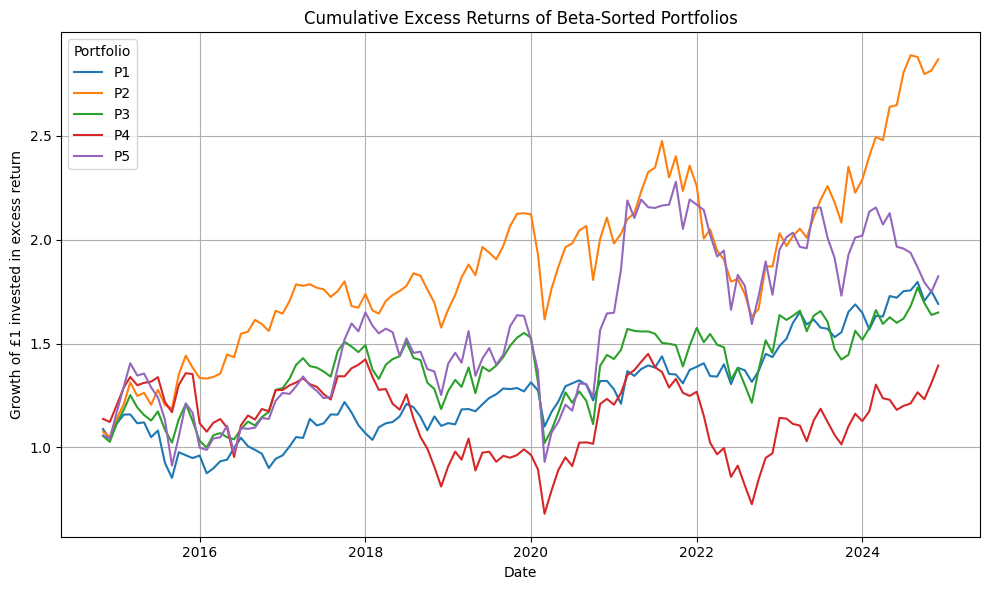

In [12]:
# =========================
# Visualisation 1: Cumulative excess returns
# =========================
cumulative_excess = (1 + portfolio_returns).cumprod()

plt.figure(figsize=(10, 6))
for col in cumulative_excess.columns:
    plt.plot(cumulative_excess.index, cumulative_excess[col], label=col)

plt.title("Cumulative Excess Returns of Beta-Sorted Portfolios")
plt.xlabel("Date")
plt.ylabel("Growth of £1 invested in excess return")
plt.legend(title="Portfolio")
plt.tight_layout()
plt.savefig("01_cumulative_excess_returns.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
# =========================
# 7. Approach 1: Time-series CAPM regressions (Refactored using apply)
# =========================

def run_ts_regression(y):
    X = sm.add_constant(market_excess.loc[y.index])
    model = sm.OLS(y, X).fit()
    return pd.Series({
        "Alpha_monthly": model.params["const"],
        "Alpha_annualised": model.params["const"] * 12,
        "Beta": model.params["Market Excess Return"],
        "Alpha_tstat": model.tvalues["const"],
        "Alpha_pvalue": model.pvalues["const"],
        "Beta_tstat": model.tvalues["Market Excess Return"],
        "R_squared": model.rsquared
    })

df_ts = portfolio_returns.apply(run_ts_regression).T
df_ts.index.name = "Portfolio"
df_ts

,Alpha_monthly,Alpha_annualised,Beta,Alpha_tstat,Alpha_pvalue,Beta_tstat,R_squared
Portfolio,,,,,,,
P1,0.0018,0.0212,0.6183,0.5647,0.5733,9.9081,0.4500
P2,0.0049,0.0594,0.8607,2.0004,0.0477,17.4758,0.7179
P3,-0.0005,-0.0055,1.0968,-0.1961,0.8449,23.4226,0.8205
P4,-0.0020,-0.0236,1.2754,-0.5716,0.5686,18.5998,0.7425
P5,-0.0000,-0.0001,1.3991,-0.0023,0.9982,20.4088,0.7763


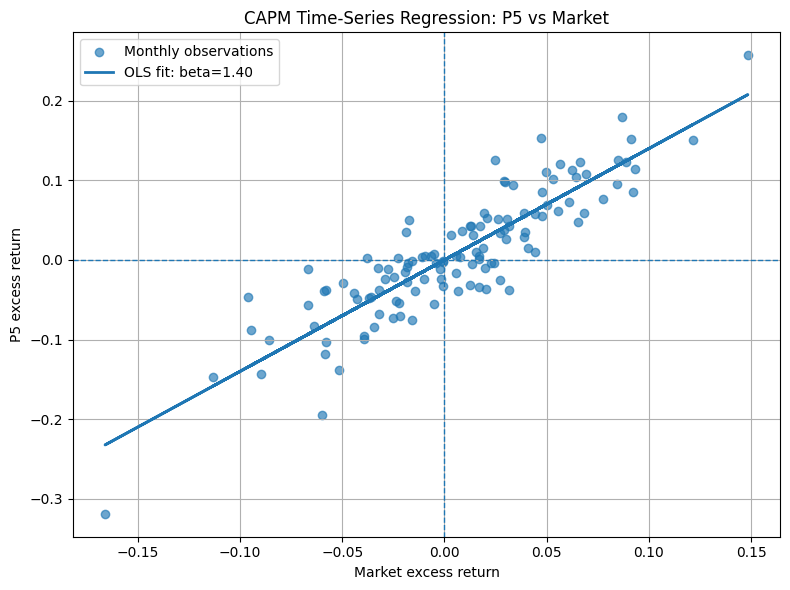

                            OLS Regression Results                            
Dep. Variable:                     P5   R-squared:                       0.776
Model:                            OLS   Adj. R-squared:                  0.774
Method:                 Least Squares   F-statistic:                     416.5
Date:                Fri, 15 May 2026   Prob (F-statistic):           7.78e-41
Time:                        14:22:54   Log-Likelihood:                 227.61
No. Observations:                 122   AIC:                            -451.2
Df Residuals:                     120   BIC:                            -445.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                -7.957e-06 

In [14]:
# =========================
# Visualisation 2: Portfolio vs market scatter plot
# Choose one representative portfolio, e.g., P5 high beta.
# =========================
portfolio_to_plot = "P5"

x = market_excess.loc[portfolio_returns.index]
y = portfolio_returns[portfolio_to_plot]

X = sm.add_constant(x)
model = sm.OLS(y, X).fit()
y_hat = model.predict(X)

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.65, label="Monthly observations")
plt.plot(x, y_hat, linewidth=2, label=f"OLS fit: beta={model.params['Market Excess Return']:.2f}")

plt.axhline(0, linewidth=1, linestyle="--")
plt.axvline(0, linewidth=1, linestyle="--")
plt.title(f"CAPM Time-Series Regression: {portfolio_to_plot} vs Market")
plt.xlabel("Market excess return")
plt.ylabel(f"{portfolio_to_plot} excess return")
plt.legend()
plt.tight_layout()
plt.savefig("02_timeseries_scatter_regression.png", dpi=300, bbox_inches="tight")
plt.show()

print(model.summary())

In [15]:
# =========================
# 8. Approach 2: Cross-sectional CAPM regression
# =========================
cs_data = pd.DataFrame({
    "Beta": df_ts["Beta"],
    "Mean_monthly_excess_return": portfolio_returns.mean(),
    "Annualised_excess_return": portfolio_returns.mean() * 12,
    "Sharpe_ratio": (portfolio_returns.mean() / portfolio_returns.std()) * np.sqrt(12),
    "Alpha_annualised": df_ts["Alpha_annualised"],
    "Alpha_pvalue": df_ts["Alpha_pvalue"],
    "R_squared": df_ts["R_squared"]
})

Y = cs_data["Mean_monthly_excess_return"]
X = sm.add_constant(cs_data["Beta"])
cs_model = sm.OLS(Y, X).fit()

cs_data

,Beta,Mean_monthly_excess_return,Annualised_excess_return,Sharpe_ratio,Alpha_annualised,Alpha_pvalue,R_squared
Portfolio,,,,,,,
P1,0.6183,0.0054,0.0645,0.4033,0.0212,0.5733,0.4500
P2,0.8607,0.0100,0.1196,0.6786,0.0594,0.0477,0.7179
P3,1.0968,0.0059,0.0712,0.3390,-0.0055,0.8449,0.8205
P4,1.2754,0.0055,0.0656,0.2555,-0.0236,0.5686,0.7425
P5,1.3991,0.0081,0.0978,0.3550,-0.0001,0.9982,0.7763


In [16]:
print(cs_model.summary())

cross_sectional_gamma = cs_model.params["const"]
cross_sectional_lambda = cs_model.params["Beta"]
average_market_premium = market_excess.mean()

print("Cross-sectional intercept gamma:", cross_sectional_gamma)
print("Cross-sectional beta premium lambda:", cross_sectional_lambda)
print("Average market excess return:", average_market_premium)

                                OLS Regression Results                                
Dep. Variable:     Mean_monthly_excess_return   R-squared:                       0.003
Model:                                    OLS   Adj. R-squared:                 -0.329
Method:                         Least Squares   F-statistic:                   0.01001
Date:                        Fri, 15 May 2026   Prob (F-statistic):              0.927
Time:                                14:22:54   Log-Likelihood:                 24.508
No. Observations:                           5   AIC:                            -45.02
Df Residuals:                               3   BIC:                            -45.80
Df Model:                                   1                                         
Covariance Type:                    nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

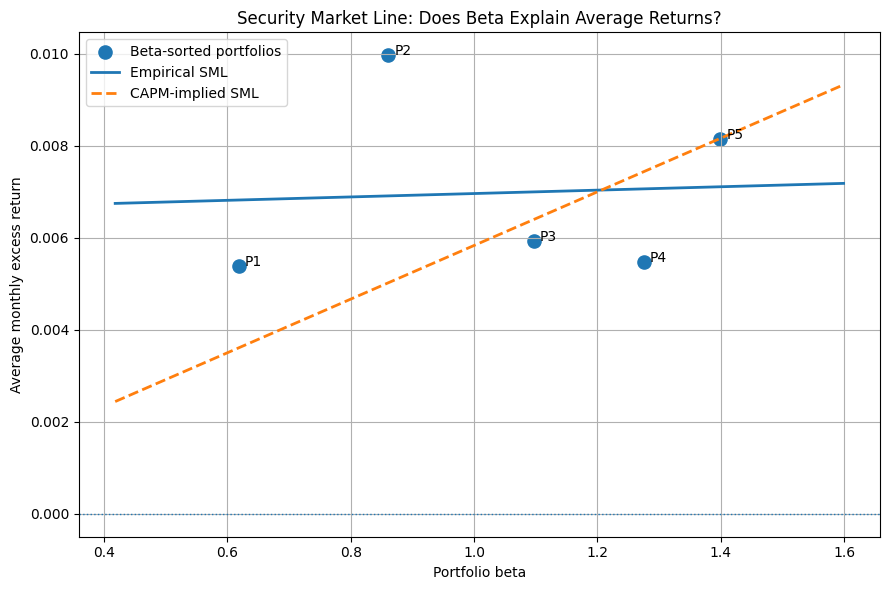

In [17]:
# =========================
# Visualisation 3: Security Market Line
# =========================
plt.figure(figsize=(9, 6))

# Scatter points: beta-sorted portfolios
plt.scatter(cs_data["Beta"], cs_data["Mean_monthly_excess_return"], s=90, label="Beta-sorted portfolios")

for p in cs_data.index:
    plt.text(
        cs_data.loc[p, "Beta"] + 0.01,
        cs_data.loc[p, "Mean_monthly_excess_return"],
        p,
        fontsize=10
    )

# Lines
x_vals = np.linspace(cs_data["Beta"].min() - 0.2, cs_data["Beta"].max() + 0.2, 100)
empirical_sml = cross_sectional_gamma + cross_sectional_lambda * x_vals
capm_sml = average_market_premium * x_vals

plt.plot(x_vals, empirical_sml, linewidth=2, label="Empirical SML")
plt.plot(x_vals, capm_sml, linestyle="--", linewidth=2, label="CAPM-implied SML")

plt.axhline(0, linewidth=1, linestyle=":")
plt.title("Security Market Line: Does Beta Explain Average Returns?")
plt.xlabel("Portfolio beta")
plt.ylabel("Average monthly excess return")
plt.legend()
plt.tight_layout()
plt.savefig("03_security_market_line.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# =========================
# 9. Approach 3: Fama-MacBeth regression (Refactored using row-wise apply)
# =========================
betas = df_ts["Beta"]
X_fm = sm.add_constant(betas)

# Run cross-sectional OLS for each month
def run_cs_reg(y_row):
    return sm.OLS(y_row, X_fm).fit().params

df_fm = portfolio_returns.apply(run_cs_reg, axis=1)
df_fm.columns = ["Gamma_t", "Lambda_t"]
df_fm.index.name = "Date"

def t_test_mean(series):
    t_stat = series.mean() / (series.std(ddof=1) / np.sqrt(series.count()))
    p_val = 2 * (1 - stats.t.cdf(abs(t_stat), df=series.count() - 1))
    return pd.Series([t_stat, p_val], index=["t_stat", "p_value"])

# Construct the final summary dataframe
fm_summary = pd.DataFrame({
    "Mean": df_fm.mean(),
    "Std": df_fm.std(ddof=1)
}).join(df_fm.apply(t_test_mean).T)

fm_summary

,Mean,Std,t_stat,p_value
Gamma_t,0.0066,0.0691,1.0528,0.2945
Lambda_t,0.0004,0.0848,0.0480,0.9618


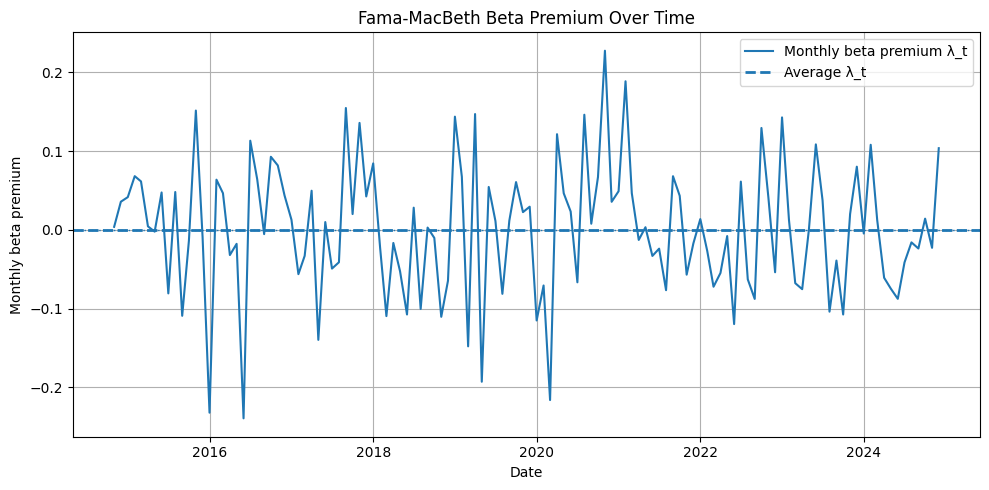

In [19]:
# =========================
# Visualisation 4: Fama-MacBeth lambda through time
# =========================
plt.figure(figsize=(10, 5))
plt.plot(df_fm.index, df_fm["Lambda_t"], label="Monthly beta premium λ_t")
plt.axhline(df_fm["Lambda_t"].mean(), linestyle="--", linewidth=2, label="Average λ_t")
plt.axhline(0, linestyle=":", linewidth=1)

plt.title("Fama-MacBeth Beta Premium Over Time")
plt.xlabel("Date")
plt.ylabel("Monthly beta premium")
plt.legend()
plt.tight_layout()
plt.savefig("04_fama_macbeth_lambda.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Performance Evaluation: Jensen's Alpha and Sharpe Ratio

These charts are useful for the final PPT because they translate regression results into investment performance.

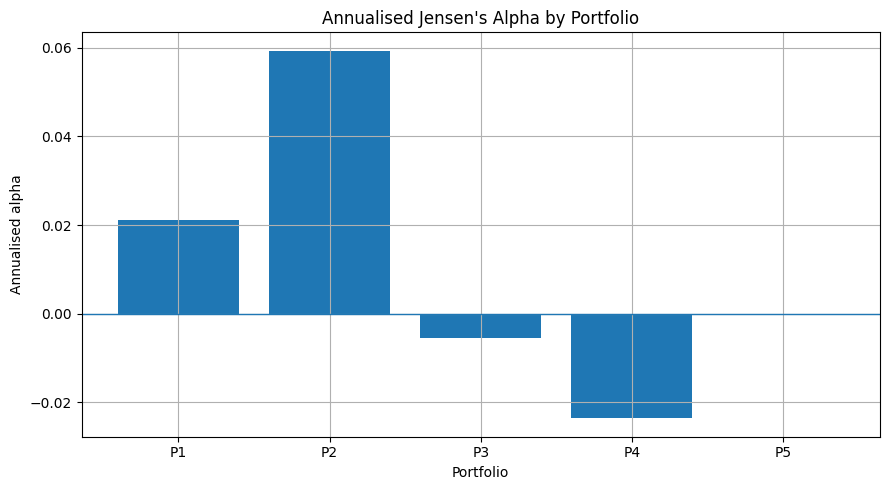

In [20]:
# =========================
# Visualisation 5: Jensen's alpha bar chart
# =========================
plt.figure(figsize=(9, 5))
plt.bar(cs_data.index, cs_data["Alpha_annualised"])
plt.axhline(0, linewidth=1)

plt.title("Annualised Jensen's Alpha by Portfolio")
plt.xlabel("Portfolio")
plt.ylabel("Annualised alpha")
plt.tight_layout()
plt.savefig("05_jensen_alpha_bar.png", dpi=300, bbox_inches="tight")
plt.show()

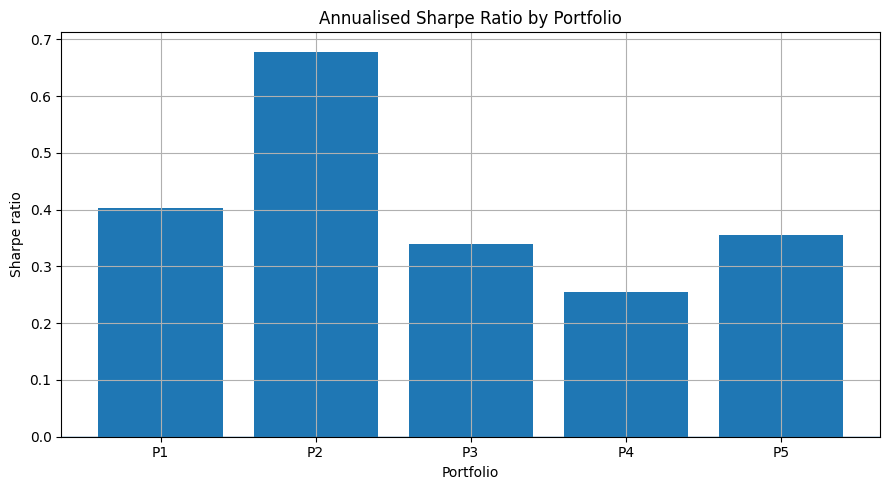

In [21]:
# =========================
# Visualisation 6: Sharpe ratio bar chart
# =========================
plt.figure(figsize=(9, 5))
plt.bar(cs_data.index, cs_data["Sharpe_ratio"])
plt.axhline(0, linewidth=1)

plt.title("Annualised Sharpe Ratio by Portfolio")
plt.xlabel("Portfolio")
plt.ylabel("Sharpe ratio")
plt.tight_layout()
plt.savefig("06_sharpe_ratio_bar.png", dpi=300, bbox_inches="tight")
plt.show()